# Order-to-delivery process: where does the time go?

Question: which steps in the order-to-delivery process take the longest, and where is the
biggest opportunity to cut total cycle time?

Data: `data/process_events.csv.gz`, a sample event log I generated with `src/generate_data.py`
(100,000 orders, 1 Aug to 29 Oct 2026, four warehouses, five stages, about 500k rows). One row per order per stage
with a start and end timestamp. The generator builds in a few operational problems on purpose
(see its docstring); this notebook tries to find them from the data alone, the way you would on
a real log.

Stages: Order Placed (payment check and release to the warehouse) -> Picked -> Packed
-> Dispatched (carrier handover) -> Delivered (last mile). Each stage starts when the
previous one ends, so an order's cycle time is the sum of its five stages.

Percentiles use the nearest-rank method (`method="inverted_cdf"`) so they match the SQL in `sql/`.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

STAGES = ["Order Placed", "Picked", "Packed", "Dispatched", "Delivered"]
WAREHOUSES = ["WH01", "WH02", "WH03", "WH04"]
PACK = "#eb6834"      # the bottleneck stage
GREY = "#b4b2a9"
INK = "#2b2a27"
WH_COLORS = dict(zip(WAREHOUSES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a887f", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e4dd", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
pd.set_option("display.width", 140)


def pct(s, q):
    """Nearest-rank percentile, same as the SQL queries."""
    return float(np.percentile(s.dropna(), q, method="inverted_cdf"))


def save(fig, name):
    fig.savefig(FIG / name)
    plt.show()

## 1. Load and check the event log

In [2]:
events = pd.read_csv(ROOT / "data" / "process_events.csv.gz", parse_dates=["StageStartTime", "StageEndTime"])
events["stage_order"] = events["Stage"].map({s: i for i, s in enumerate(STAGES, 1)})
events["duration_min"] = (events["StageEndTime"] - events["StageStartTime"]).dt.total_seconds() / 60

stage_counts = events.groupby("OrderID").agg(stages=("Stage", "size"), ended=("StageEndTime", "count"))
complete_ids = stage_counts.index[(stage_counts.stages == 5) & (stage_counts.ended == 5)]

print(f"{len(events):,} rows, {events.OrderID.nunique()} orders, "
      f"{events.StageStartTime.min():%d %b} to {events.StageStartTime.max():%d %b %Y}")
print(f"Delivered orders: {len(complete_ids)}; still in flight at the data pull: "
      f"{events.OrderID.nunique() - len(complete_ids)}")
print("Negative durations:", (events.duration_min < 0).sum())
print("Duplicate order/stage rows:", events.duplicated(["OrderID", "Stage"]).sum())

ordered = events.sort_values(["OrderID", "stage_order"])
gaps = ordered.groupby("OrderID")["StageEndTime"].shift() != ordered["StageStartTime"]
print("Stage gaps/overlaps:", (gaps & ordered.groupby("OrderID").cumcount().gt(0)).sum())
events[events.OrderID.isin(set(events.OrderID) - set(complete_ids))]

499,445 rows, 100000 orders, 01 Aug to 29 Oct 2026
Delivered orders: 99690; still in flight at the data pull: 310
Negative durations: 0
Duplicate order/stage rows: 0


Stage gaps/overlaps: 0


,OrderID,Stage,StageStartTime,StageEndTime,WarehouseID,Region,stage_order,duration_min
495305,ORD-109062,Order Placed,2026-10-29 12:28:14,2026-10-29 12:53:44,WH03,South,1,25.500000
495306,ORD-109062,Picked,2026-10-29 12:53:44,2026-10-29 13:30:22,WH03,South,2,36.633333
495307,ORD-109062,Packed,2026-10-29 13:30:22,NaT,WH03,South,3,NaN
495618,ORD-109125,Order Placed,2026-10-29 13:09:53,2026-10-29 13:49:40,WH03,East,1,39.783333
495619,ORD-109125,Picked,2026-10-29 13:49:40,2026-10-29 14:21:31,WH03,East,2,31.850000
...,...,...,...,...,...,...,...,...
499440,ORD-109996,Order Placed,2026-10-29 23:49:47,NaT,WH04,East,1,NaN
499441,ORD-109997,Order Placed,2026-10-29 23:49:53,NaT,WH04,South,1,NaN
499442,ORD-109998,Order Placed,2026-10-29 23:52:53,NaT,WH03,South,1,NaN
499443,ORD-109999,Order Placed,2026-10-29 23:55:02,NaT,WH02,West,1,NaN


The three in-flight orders were placed on the last evening and are still being packed or
dispatched. Their finished stages are kept for the stage-level stats, but they're left out of
anything that needs an end-to-end cycle time.

In [3]:
durations = events.dropna(subset=["StageEndTime"]).copy()
done = durations[durations.OrderID.isin(complete_ids)]

orders = done.pivot_table(index="OrderID", columns="Stage", values="duration_min")[STAGES]
meta = done.groupby("OrderID").agg(WarehouseID=("WarehouseID", "first"), Region=("Region", "first"),
                                   placed_at=("StageStartTime", "min"), delivered_at=("StageEndTime", "max"))
orders = meta.join(orders)
orders["cycle_hours"] = orders[STAGES].sum(axis=1) / 60
orders.head()

,WarehouseID,Region,placed_at,delivered_at,Order Placed,Picked,Packed,Dispatched,Delivered,cycle_hours
OrderID,,,,,,,,,,
ORD-100000,WH01,North,2026-10-22 17:14:01,2026-10-22 19:35:31,31.916667,18.600000,19.816667,15.916667,55.250000,2.358333
ORD-100001,WH01,West,2026-10-22 17:14:43,2026-10-22 20:38:06,24.550000,43.900000,89.400000,10.650000,34.883333,3.389722
ORD-100002,WH01,North,2026-10-22 17:14:44,2026-10-22 19:36:23,31.400000,29.383333,30.716667,37.183333,12.966667,2.360833
ORD-100003,WH02,West,2026-10-22 17:15:39,2026-10-22 22:58:12,24.000000,90.500000,140.416667,74.833333,12.800000,5.709167
ORD-100004,WH03,South,2026-10-22 17:16:21,2026-10-22 22:22:40,46.533333,47.550000,158.983333,30.800000,22.450000,5.105278


## 2. Average vs P90 by stage

The average alone hides the problem. Every stage except Packing has a P90 about 1.6x its mean,
which is what normal process noise looks like. Packing's P90 is 2.3x its mean, and its median is
less than half its mean: most orders pack in under two hours, but a long tail sits on the bench
for 10 hours or more.

In [4]:
summary = durations.groupby("Stage")["duration_min"].agg(
    orders="size", avg_min="mean",
    p50_min=lambda s: pct(s, 50), p90_min=lambda s: pct(s, 90), p95_min=lambda s: pct(s, 95), max_min="max")
summary["p90_to_avg"] = summary.p90_min / summary.avg_min
summary["pct_of_total_time"] = 100 * durations.groupby("Stage").duration_min.sum() / durations.duration_min.sum()
summary = summary.reindex(STAGES).round(1)

sql_summary = pd.read_csv(ROOT / "outputs" / "03_stage_summary.csv").set_index("Stage")
assert np.allclose(summary.loc[sql_summary.index, ["avg_min", "p90_min"]], sql_summary[["avg_min", "p90_min"]], atol=0.15), \
    "Python and SQL disagree"
summary

,orders,avg_min,p50_min,p90_min,p95_min,max_min,p90_to_avg,pct_of_total_time
Stage,,,,,,,,
Order Placed,99984,29.9,27.0,48.2,56.6,177.8,1.6,7.6
Picked,99963,40.0,36.2,64.6,75.9,255.1,1.6,10.1
Packed,99762,249.1,116.7,583.6,935.5,2970.2,2.3,62.9
Dispatched,99736,40.0,36.2,64.3,75.6,233.0,1.6,10.1
Delivered,99690,36.6,32.9,59.3,69.9,260.5,1.6,9.2


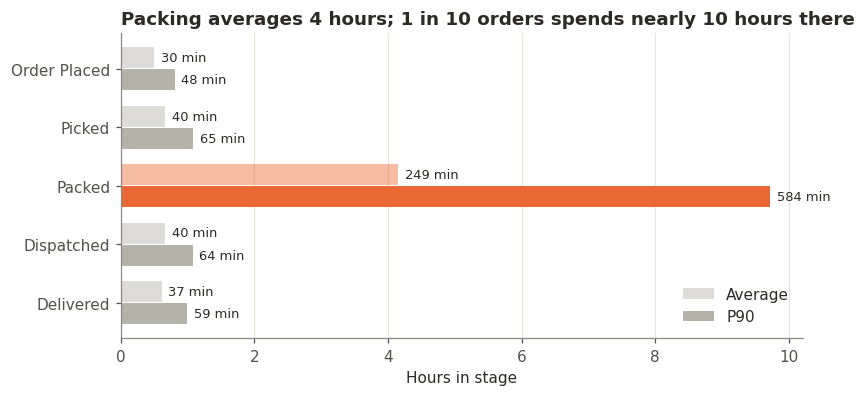

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(STAGES))[::-1]
colors = [PACK if s == "Packed" else GREY for s in STAGES]
ax.barh(y + 0.19, summary.avg_min / 60, height=0.36, color=colors, alpha=0.45, label="Average")
ax.barh(y - 0.19, summary.p90_min / 60, height=0.36, color=colors, label="P90")
for yi, s in zip(y, STAGES):
    ax.text(summary.loc[s, "avg_min"] / 60 + 0.1, yi + 0.19, f"{summary.loc[s, 'avg_min']:.0f} min", va="center", fontsize=8.5)
    ax.text(summary.loc[s, "p90_min"] / 60 + 0.1, yi - 0.19, f"{summary.loc[s, 'p90_min']:.0f} min", va="center", fontsize=8.5)
ax.set_yticks(y, STAGES)
ax.set_xlabel("Hours in stage")
ax.set_title("Packing averages 4 hours; 1 in 10 orders spends nearly 10 hours there")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
save(fig, "01_avg_vs_p90_by_stage.png")

## 3. Distribution of time per stage

Box plot of every order's time in each stage. Log scale on the right so the four quick stages
are still readable.

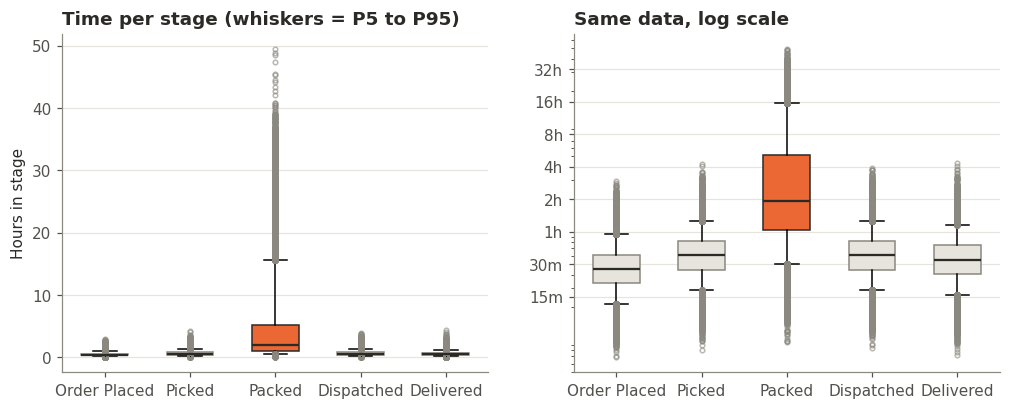

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1]})
data = [durations.loc[durations.Stage == s, "duration_min"] / 60 for s in STAGES]
for ax, log in zip(axes, [False, True]):
    bp = ax.boxplot(data, tick_labels=STAGES, patch_artist=True, widths=0.55, whis=(5, 95),
                    medianprops={"color": INK, "linewidth": 1.5},
                    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "none", "markeredgecolor": "#8a887f", "alpha": 0.6})
    for patch, s in zip(bp["boxes"], STAGES):
        patch.set_facecolor(PACK if s == "Packed" else "#e6e4dd")
        patch.set_edgecolor(INK if s == "Packed" else "#8a887f")
    ax.grid(axis="x", visible=False)
    if log:
        ax.set_yscale("log")
        ax.set_yticks([0.25, 0.5, 1, 2, 4, 8, 16, 32], ["15m", "30m", "1h", "2h", "4h", "8h", "16h", "32h"])
        ax.set_title("Same data, log scale")
    else:
        ax.set_ylabel("Hours in stage")
        ax.set_title("Time per stage (whiskers = P5 to P95)")
save(fig, "02_stage_duration_boxplot.png")

## 4. End-to-end cycle time, and what makes an order slow

In [7]:
cyc = orders.cycle_hours
cycle_stats = pd.Series({"avg": cyc.mean(), "p50": pct(cyc, 50), "p90": pct(cyc, 90), "p95": pct(cyc, 95),
                         "max": cyc.max(), "over_12h": (cyc > 12).sum(), "over_24h": (cyc > 24).sum()}).round(2)
cycle_stats

avg             6.59
p50             4.49
p90            12.32
p95            17.98
max            52.36
over_12h    10681.00
over_24h     2027.00
dtype: float64

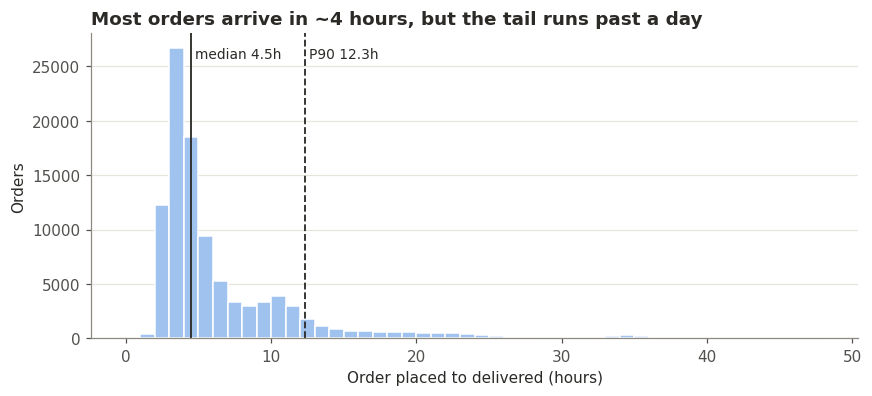

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(cyc, bins=np.arange(0, 49, 1), color="#9fc3ee", edgecolor="white", linewidth=1)
for label, v, ls in [("median", cycle_stats.p50, "-"), ("P90", cycle_stats.p90, "--")]:
    ax.axvline(v, color=INK, linestyle=ls, linewidth=1.2)
    ax.text(v + 0.3, ax.get_ylim()[1] * 0.92, f"{label} {v:.1f}h", fontsize=9)
ax.set_xlabel("Order placed to delivered (hours)")
ax.set_ylabel("Orders")
ax.set_title("Most orders arrive in ~4 hours, but the tail runs past a day")
ax.grid(axis="x", visible=False)
save(fig, "03_cycle_time_distribution.png")

Which stage contributes most to the slow orders? Split orders into cycle-time bands and look at
how each band's time is divided between stages.

In [9]:
orders["band"] = pd.cut(orders.cycle_hours, [0, 12, 24, np.inf], labels=["Under 12h", "12-24h", "Over 24h"])
band_share = orders.groupby("band", observed=True)[STAGES].sum()
band_share = band_share.div(band_share.sum(axis=1), axis=0) * 100
band_share.insert(0, "orders", orders.band.value_counts())
band_share.round(1)

,orders,Order Placed,Picked,Packed,Dispatched,Delivered
band,,,,,,
Under 12h,89009,9.8,13.1,52.0,13.1,12.0
12-24h,8654,3.1,4.3,84.6,4.2,3.8
Over 24h,2027,1.6,2.2,91.9,2.2,2.0


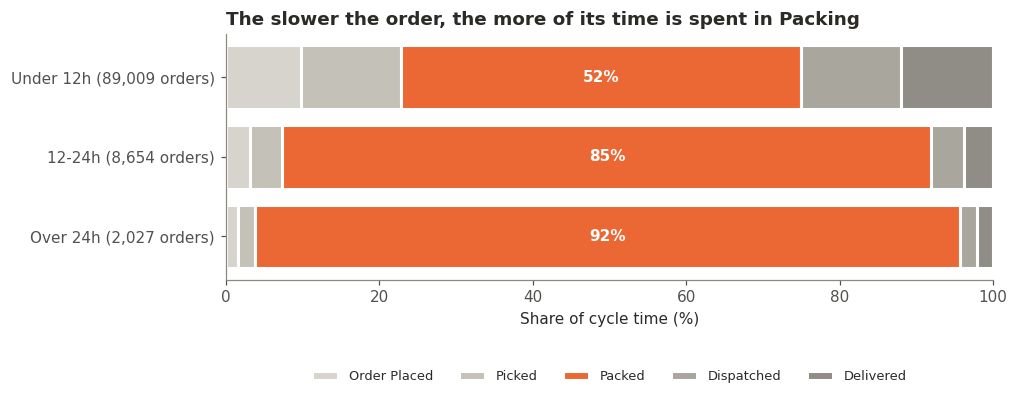

In [10]:
fig, ax = plt.subplots(figsize=(9, 2.9))
bands = band_share.index[::-1]
left = np.zeros(len(bands))
stage_colors = {"Order Placed": "#d6d4cc", "Picked": "#c3c1b8", "Packed": PACK, "Dispatched": "#a8a69d", "Delivered": "#8f8d85"}
for s in STAGES:
    vals = band_share.loc[bands, s].values
    ax.barh(range(len(bands)), vals, left=left, color=stage_colors[s], edgecolor="white", linewidth=2, label=s)
    if s == "Packed":
        for i, v in enumerate(vals):
            ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    left += vals
ax.set_yticks(range(len(bands)), [f"{b} ({band_share.loc[b, 'orders']:,} orders)" for b in bands])
ax.set_xlim(0, 100)
ax.set_xlabel("Share of cycle time (%)")
ax.set_title("The slower the order, the more of its time is spent in Packing")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.32), frameon=False, fontsize=8.5)
ax.grid(False)
save(fig, "04_stage_share_by_cycle_band.png")

For the roughly 2,000 orders that took over 24 hours (2% of deliveries), Packing is 92% of their time. Even for the "normal" orders under
12 hours, it's half. Nothing else comes close, so the rest of the notebook looks inside Packing.

## 5. Is Packing slow everywhere? Warehouse and region

In [11]:
pack = durations[durations.Stage == "Packed"].copy()
pack["arrive_hour"] = pack.StageStartTime.dt.hour
pack["arrive_day"] = pack.StageStartTime.dt.day_name().str[:3]

by_wh = pack.groupby("WarehouseID").duration_min.agg(
    orders="size", avg_min="mean", p50_min=lambda s: pct(s, 50), p90_min=lambda s: pct(s, 90),
    pct_over_4h=lambda s: 100 * (s > 240).mean())
by_wh["avg_cycle_hours"] = orders.groupby("WarehouseID").cycle_hours.mean()
by_wh["pct_cycle_over_12h"] = orders.groupby("WarehouseID").cycle_hours.apply(lambda s: 100 * (s > 12).mean())
by_wh.round(1)

,orders,avg_min,p50_min,p90_min,pct_over_4h,avg_cycle_hours,pct_cycle_over_12h
WarehouseID,,,,,,,
WH01,29939,139.8,80.3,421.2,16.8,4.8,1.2
WH02,27800,288.6,113.7,834.9,30.0,7.3,15.6
WH03,23907,417.9,258.9,990.9,53.0,9.4,23.9
WH04,18116,146.1,86.8,426.0,17.5,4.9,1.6


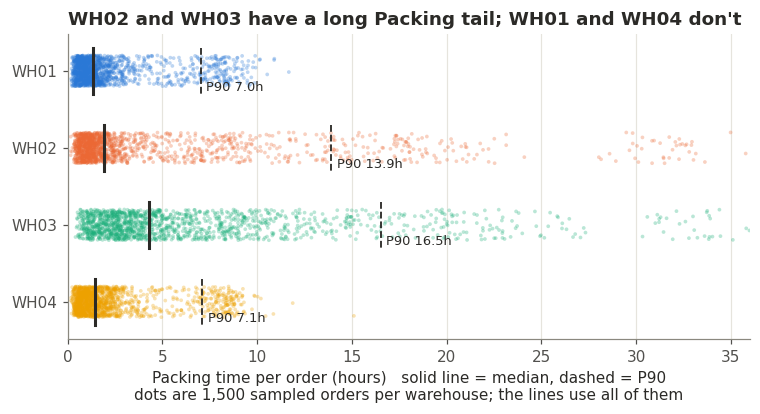

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, wh in enumerate(WAREHOUSES):
    vals = pack.loc[pack.WarehouseID == wh, "duration_min"] / 60
    shown = vals.sample(1500, random_state=i)  # plot a sample; the lines use every order
    jitter = np.random.default_rng(i).uniform(-0.2, 0.2, len(shown))
    ax.scatter(shown, i + jitter, s=6, color=WH_COLORS[wh], alpha=0.3, edgecolor="none")
    ax.plot([pct(vals, 50)] * 2, [i - 0.3, i + 0.3], color=INK, linewidth=2)
    ax.plot([pct(vals, 90)] * 2, [i - 0.3, i + 0.3], color=INK, linewidth=1.2, linestyle="--")
    ax.text(pct(vals, 90) + 0.3, i + 0.3, f"P90 {pct(vals, 90):.1f}h", fontsize=8.5, va="bottom")
ax.set_yticks(range(4), WAREHOUSES)
ax.invert_yaxis()
ax.set_xlabel("Packing time per order (hours)   solid line = median, dashed = P90\n"
              "dots are 1,500 sampled orders per warehouse; the lines use all of them")
ax.set_xlim(0, 36)
ax.set_title("WH02 and WH03 have a long Packing tail; WH01 and WH04 don't")
ax.grid(axis="y", visible=False)
save(fig, "05_packing_by_warehouse.png")

Is it the warehouse or the delivery region? Average time in each stage for every
warehouse/region pair. Only the Packing column moves with the warehouse; the delivery region
barely matters (cross-region deliveries add ~10 minutes to the last mile, that's all).

In [13]:
wr = durations.pivot_table(index=["WarehouseID", "Region"], columns="Stage", values="duration_min",
                           aggfunc="mean")[STAGES]
wr.insert(0, "orders", durations[durations.Stage == "Order Placed"].groupby(["WarehouseID", "Region"]).size())
wr.round(0)

Stage               orders  Order Placed  Picked  Packed  Dispatched  Delivered
WarehouseID Region                                                             
WH01        East      1874          30.0    39.0   141.0        40.0       44.0
            North    24447          30.0    40.0   140.0        40.0       35.0
            South     1811          30.0    39.0   140.0        39.0       43.0
            West      1855          30.0    40.0   142.0        40.0       44.0
WH02        East      1665          30.0    39.0   290.0        40.0       44.0
            North     1635          30.0    40.0   292.0        40.0       44.0
            South     1652          30.0    40.0   294.0        40.0       44.0
            West     22913          30.0    40.0   288.0        40.0       35.0
WH03        East      1450          30.0    40.0   397.0        39.0       43.0
            North     1429          30.0    39.0   414.0        40.0       44.0
            South    19642          30.0    40.0   418.0        40.0       35.0
            West      1467          30.0    40.0   436.0        40.0       45.0
WH04        East     14927          30.0    40.0   146.0        40.0       35.0
            North     1067          30.0    40.0   144.0        40.0       43.0
            South     1096          30.0    40.0   151.0        40.0       44.0
            West      1054          30.0    40.0   141.0        40.0       43.0

In [14]:
# Kruskal-Wallis (durations are skewed, so no ANOVA): does Packing time differ by warehouse?
# And within each warehouse's own home-region orders vs the rest?
kw_wh = stats.kruskal(*[g.duration_min for _, g in pack.groupby("WarehouseID")])
kw_region = stats.kruskal(*[g.duration_min for _, g in pack.groupby("Region")])
print(f"Packing by warehouse: H = {kw_wh.statistic:.1f}, p = {kw_wh.pvalue:.1e}")
print(f"Packing by region:    H = {kw_region.statistic:.1f}, p = {kw_region.pvalue:.1e}")
home = {"WH01": "North", "WH02": "West", "WH03": "South", "WH04": "East"}
pack["home_region"] = pack.Region == pack.WarehouseID.map(home)
within = [stats.mannwhitneyu(g[g.home_region].duration_min, g[~g.home_region].duration_min).pvalue
          for _, g in pack.groupby("WarehouseID")]
print("Home vs other region, inside each warehouse (Mann-Whitney p):", [f"{p:.2f}" for p in within])

Packing by warehouse: H = 17431.9, p = 0.0e+00
Packing by region:    H = 10139.4, p = 0.0e+00
Home vs other region, inside each warehouse (Mann-Whitney p): ['0.97', '0.53', '0.45', '0.90']


The region effect is only there because each region is mostly served by one warehouse. Inside a
warehouse, orders going to another region pack no slower (all p > 0.4). So this is a warehouse
problem, not a geography one.

## 6. When does Packing go wrong? Time of day and day of week

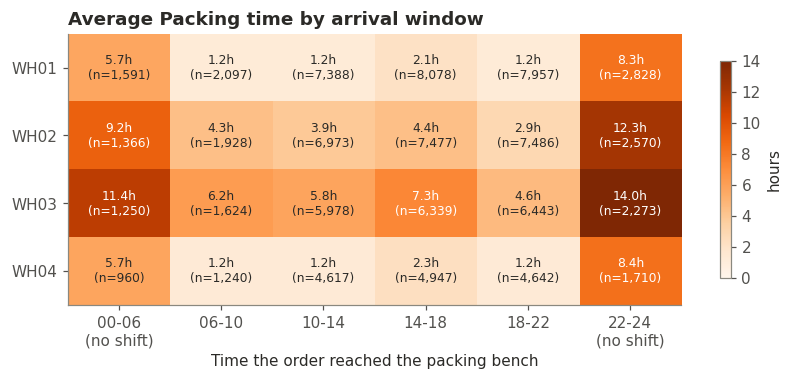

In [15]:
windows = pd.cut(pack.arrive_hour, [-1, 5, 9, 13, 17, 21, 23],
                 labels=["00-06\n(no shift)", "06-10", "10-14", "14-18", "18-22", "22-24\n(no shift)"])
pack["window"] = windows
heat = pack.pivot_table(index="WarehouseID", columns="window", values="duration_min", aggfunc="mean", observed=False) / 60
heat_n = pack.pivot_table(index="WarehouseID", columns="window", values="duration_min", aggfunc="size", observed=False)

fig, ax = plt.subplots(figsize=(9, 3.2))
im = ax.imshow(heat.values, cmap="Oranges", aspect="auto", vmin=0, vmax=14)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.1f}h\n(n={heat_n.values[i, j]:,})", ha="center", va="center", fontsize=8,
                color="white" if v > 7 else INK)
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.set_xlabel("Time the order reached the packing bench")
ax.set_title("Average Packing time by arrival window")
ax.grid(False)
fig.colorbar(im, ax=ax, label="hours", shrink=0.8)
save(fig, "06_packing_heatmap_warehouse_by_hour.png")

Three things show up:

1. Nothing gets packed overnight. 88% of orders reaching packing between midnight and 06:00, and
   every order arriving 22:00-24:00, took over 4 hours. They wait for the morning shift, at every warehouse.
2. 14:00-18:00 is the slowest daytime window at every warehouse. At WH01 and WH04 afternoon
   arrivals take about 1.8x as long as morning ones (2.1-2.3h vs 1.2h). The queue builds when the
   shift is busiest.
3. WH03 is slower in every window, so on top of the shift pattern it's short of capacity.

Day of week next. First, who actually packs on Sundays? Then WH02 + WH03 vs WH01 + WH04.

Packing jobs finished on a Sunday, 08:00-22:00: {'WH01': 3291, 'WH02': 0, 'WH03': 35, 'WH04': 2004}


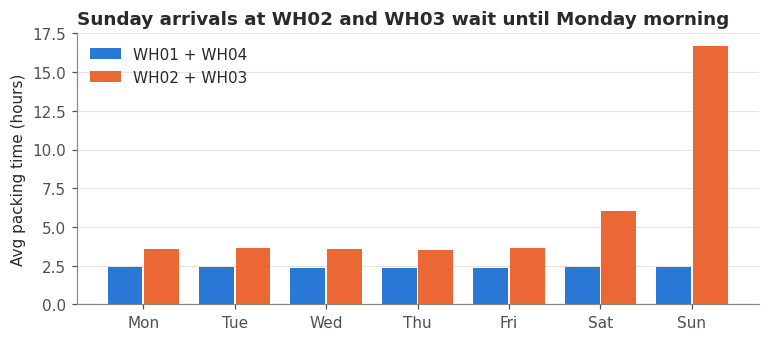

In [16]:
day_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
pack["sunday_shift"] = np.where(pack.WarehouseID.isin(["WH01", "WH04"]), "WH01 + WH04", "WH02 + WH03")
dow = pack.pivot_table(index="arrive_day", columns="sunday_shift", values="duration_min", aggfunc="mean").loc[day_order] / 60

# Who actually packs on Sundays? Count packing jobs finished on a Sunday between 08:00 and 22:00
# (Saturday-evening jobs that run past midnight would otherwise blur the picture).
done_pack = durations[durations.Stage == "Packed"]
sunday_day = done_pack[(done_pack.StageEndTime.dt.dayofweek == 6) & done_pack.StageEndTime.dt.hour.between(8, 21)]
print("Packing jobs finished on a Sunday, 08:00-22:00:",
      sunday_day.WarehouseID.value_counts().reindex(WAREHOUSES, fill_value=0).to_dict())

fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(7)
ax.bar(x - 0.2, dow["WH01 + WH04"], width=0.38, color="#2a78d6", label="WH01 + WH04")
ax.bar(x + 0.2, dow["WH02 + WH03"], width=0.38, color=PACK, label="WH02 + WH03")
ax.set_xticks(x, day_order)
ax.set_ylabel("Avg packing time (hours)")
ax.set_title("Sunday arrivals at WH02 and WH03 wait until Monday morning")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
save(fig, "07_packing_by_weekday.png")

Across 13 Sundays, WH02 finished no packing jobs during the day and WH03 finished 35 (vs 3,291 at
WH01). Neither runs a Sunday packing shift, so anything that reaches their benches on a Sunday
sits there ~17 hours on average, until Monday 06:00. Saturday is worse too (6h), because evening
arrivals roll straight into the Sunday gap.

## 7. 90-day trend

In [17]:
orders["week"] = orders.placed_at.dt.to_period("W-SUN").dt.start_time
# 1 Aug is a Saturday and the data stops on 29 Oct, so the first and last weeks are partial: drop them.
full_weeks = orders.week.between(pd.Timestamp("2026-08-03"), pd.Timestamp("2026-10-19"))
orders_w = orders[full_weeks]
weekly = orders_w.groupby("week").agg(orders=("cycle_hours", "size"), packed_min=("Packed", "mean"),
                                    cycle_hours=("cycle_hours", "mean"),
                                    p90_cycle=("cycle_hours", lambda s: pct(s, 90)))
wh03_weekly = orders_w[orders_w.WarehouseID == "WH03"].groupby("week").Packed.mean()
others_weekly = orders_w[orders_w.WarehouseID != "WH03"].groupby("week").Packed.mean()
other_stages_weekly = orders_w.groupby("week")[["Order Placed", "Picked", "Dispatched", "Delivered"]].mean().sum(axis=1)
weekly.round(1)

,orders,packed_min,cycle_hours,p90_cycle
week,,,,
2026-08-03,6178,237.6,6.4,11.9
2026-08-10,6530,244.7,6.5,12.2
2026-08-17,6811,236.0,6.4,11.9
2026-08-24,7064,233.3,6.3,11.8
2026-08-31,7275,241.7,6.5,12.0
2026-09-07,7534,239.9,6.4,11.9
2026-09-14,7954,254.7,6.7,12.6
2026-09-21,8010,260.7,6.8,12.8
2026-09-28,8407,257.8,6.7,12.7


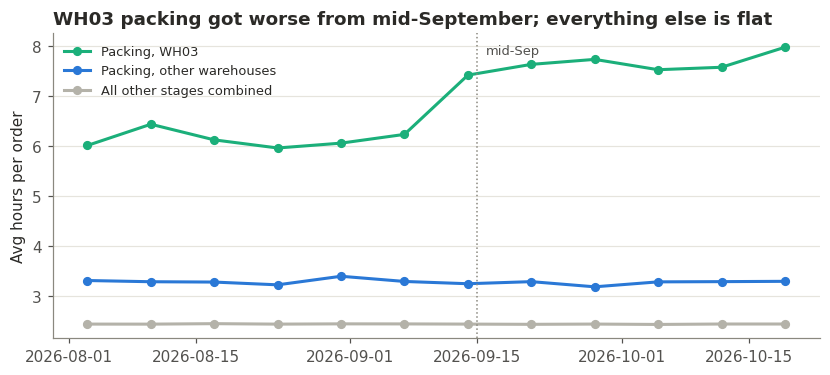

                    orders  avg_pack_min  p90_pack_min
WH03 before 15 Sep   10650         379.0         968.0
WH03 from 15 Sep     13224         450.0        1008.0
Mann-Whitney p: 6.4e-144


In [18]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(wh03_weekly.index, wh03_weekly / 60, color="#1baf7a", linewidth=2, marker="o", markersize=5, label="Packing, WH03")
ax.plot(others_weekly.index, others_weekly / 60, color="#2a78d6", linewidth=2, marker="o", markersize=5, label="Packing, other warehouses")
ax.plot(other_stages_weekly.index, other_stages_weekly / 60, color=GREY, linewidth=2, marker="o", markersize=5,
        label="All other stages combined")
ax.axvline(pd.Timestamp("2026-09-15"), color="#8a887f", linestyle=":", linewidth=1)
ax.text(pd.Timestamp("2026-09-16"), ax.get_ylim()[1] * 0.95, "mid-Sep", fontsize=8.5, color="#52514e")
ax.set_ylabel("Avg hours per order")
ax.set_title("WH03 packing got worse from mid-September; everything else is flat")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.grid(axis="x", visible=False)
save(fig, "08_weekly_trend.png")

before_after = orders[orders.WarehouseID == "WH03"].groupby(orders.placed_at >= "2026-09-15").Packed.agg(["size", "mean", lambda s: pct(s, 90)])
before_after.index = ["WH03 before 15 Sep", "WH03 from 15 Sep"]
before_after.columns = ["orders", "avg_pack_min", "p90_pack_min"]
print(before_after.round(0))
print(f"Mann-Whitney p: {stats.mannwhitneyu(*[g.Packed for _, g in orders[orders.WarehouseID == 'WH03'].groupby(orders.placed_at >= '2026-09-15')]).pvalue:.1e}")

The other stages are flat across all 13 weeks, and so is Packing at the other three
warehouses. WH03's Packing average steps up from mid-September and stays there. That's the
pattern you'd expect from a staffing change rather than demand (order volume grows gradually,
not in a step). Worth asking the WH03 site lead what changed that week.

## 8. What would fixing Packing be worth?

Because the stages run back to back, I can replace an order's Packing time and recompute its
cycle time and delivery time directly. Two outcome measures:

- P90 cycle time (what 1 in 10 customers experiences)
- Same-day promise: orders placed before 14:00 should be delivered the same calendar day.

Scenarios, from most targeted to broadest:

- A. Night packing cover: orders that reach packing 22:00-06:00 get the median packing time
  of that warehouse's daytime arrivals (as if a skeleton night team cleared them).
- B. Sunday shift at WH02 + WH03: Sunday arrivals there get that warehouse's weekday median.
- C. Afternoon peak staffing: 14:00-18:00 arrivals get the 06:00-14:00 median of their warehouse.
- D. WH03 back to pre-September capacity: WH03 orders from 15 Sep get their packing time scaled
  by the before/after ratio of medians.
- A + B + C + D together.
- Benchmark: every warehouse packs like WH01 (each order's packing time is mapped to the same
  percentile of WH01's distribution).

In [19]:
p = orders.copy()
p_meta = pack.set_index("OrderID").loc[p.index, ["arrive_hour", "StageStartTime"]]
p["arrive_hour"] = p_meta.arrive_hour
p["arrive_dow"] = p_meta.StageStartTime.dt.dayofweek
p["night"] = (p.arrive_hour >= 22) | (p.arrive_hour < 6)
p["afternoon"] = p.arrive_hour.between(14, 17)

day_median = p[~p.night].groupby("WarehouseID").Packed.median()
weekday_median = p[(p.arrive_dow < 6) & ~p.night].groupby("WarehouseID").Packed.median()
morning_median = p[p.arrive_hour.between(6, 13)].groupby("WarehouseID").Packed.median()
wh03 = p.WarehouseID == "WH03"
late = p.placed_at >= "2026-09-15"
wh03_ratio = p.loc[wh03 & ~late, "Packed"].median() / p.loc[wh03 & late, "Packed"].median()


def fix_night(df):
    m = df.night
    df.loc[m, "Packed"] = np.minimum(df.loc[m, "Packed"], df.loc[m, "WarehouseID"].map(day_median))
    return df


def fix_sunday(df):
    m = (df.arrive_dow == 6) & df.WarehouseID.isin(["WH02", "WH03"])
    df.loc[m, "Packed"] = np.minimum(df.loc[m, "Packed"], df.loc[m, "WarehouseID"].map(weekday_median))
    return df


def fix_afternoon(df):
    m = df.afternoon
    df.loc[m, "Packed"] = np.minimum(df.loc[m, "Packed"], df.loc[m, "WarehouseID"].map(morning_median))
    return df


def fix_wh03(df):
    m = (df.WarehouseID == "WH03") & (df.placed_at >= "2026-09-15")
    df.loc[m, "Packed"] = df.loc[m, "Packed"] * wh03_ratio
    return df


def benchmark_wh01(df):
    wh01 = np.sort(p.loc[p.WarehouseID == "WH01", "Packed"].values)
    ranks = df.groupby("WarehouseID").Packed.rank(pct=True)
    df["Packed"] = np.quantile(wh01, ranks.clip(upper=1.0), method="inverted_cdf")
    return df


def outcome(df):
    cyc = df[STAGES].sum(axis=1) / 60
    delivered = df.placed_at + pd.to_timedelta(cyc, unit="h")
    promised = df.placed_at.dt.hour < 14
    same_day_miss = (delivered[promised].dt.date != df.placed_at[promised].dt.date).mean() * 100
    return {"avg_pack_min": df.Packed.mean(), "avg_cycle_h": cyc.mean(), "p90_cycle_h": pct(cyc, 90),
            "p95_cycle_h": pct(cyc, 95), "orders_over_12h": int((cyc > 12).sum()),
            "orders_over_24h": int((cyc > 24).sum()), "same_day_miss_pct": same_day_miss}


scenarios = {
    "Current": lambda d: d,
    "A. Night packing cover": fix_night,
    "B. Sunday shift WH02+WH03": fix_sunday,
    "C. Afternoon peak staffing": fix_afternoon,
    "D. WH03 back to pre-Sep": fix_wh03,
    "A+B+C+D": lambda d: fix_wh03(fix_afternoon(fix_sunday(fix_night(d)))),
    "Benchmark: all pack like WH01": benchmark_wh01,
}
results = pd.DataFrame({name: outcome(f(p.copy())) for name, f in scenarios.items()}).T
results.round(1)

,avg_pack_min,avg_cycle_h,p90_cycle_h,p95_cycle_h,orders_over_12h,orders_over_24h,same_day_miss_pct
Current,249.1,6.6,12.3,18.0,10681.0,2027.0,8.3
A. Night packing cover,179.8,5.4,8.5,15.8,7171.0,871.0,7.9
B. Sunday shift WH02+WH03,184.9,5.5,10.1,11.5,3906.0,802.0,1.0
C. Afternoon peak staffing,208.8,5.9,11.2,14.5,7918.0,1954.0,6.2
D. WH03 back to pre-Sep,230.7,6.3,11.6,16.4,9111.0,1624.0,7.8
A+B+C+D,92.8,4.0,5.4,6.1,80.0,0.0,0.1
Benchmark: all pack like WH01,139.8,4.8,9.4,10.7,1257.0,0.0,0.5


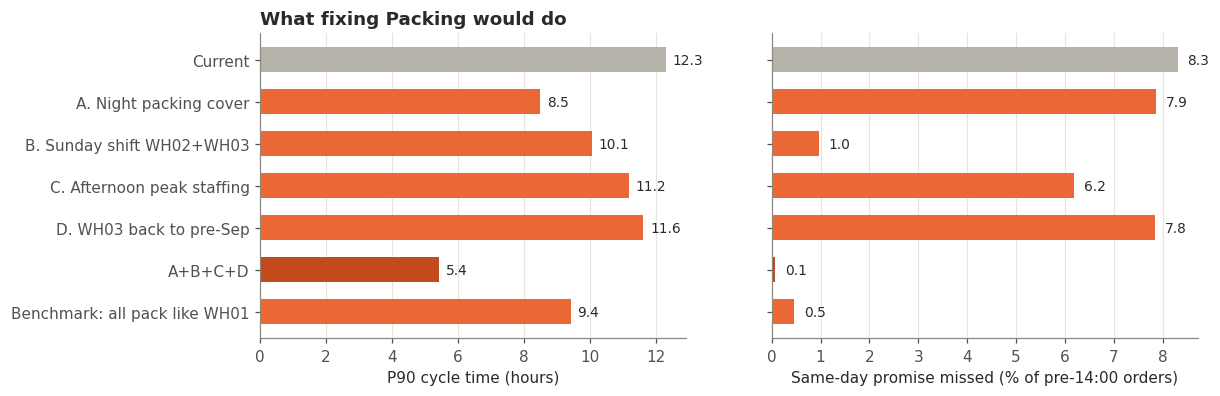

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
names = results.index[::-1]
for ax, col, label in [(axes[0], "p90_cycle_h", "P90 cycle time (hours)"),
                       (axes[1], "same_day_miss_pct", "Same-day promise missed (% of pre-14:00 orders)")]:
    colors = [GREY if n == "Current" else ("#c24a1c" if n == "A+B+C+D" else PACK) for n in names]
    ax.barh(range(len(names)), results.loc[names, col], color=colors, height=0.6)
    for i, n in enumerate(names):
        ax.text(results.loc[n, col] + 0.2, i, f"{results.loc[n, col]:.1f}", va="center", fontsize=9)
    ax.set_xlabel(label)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(names)), names)
axes[0].set_title("What fixing Packing would do")
save(fig, "09_scenarios.png")

## 9. Takeaways

The numbers below come from the tables above; the write-up with the recommendation is in
`reports/recommendation.md`.

In [21]:
cur, combo, a = results.loc["Current"], results.loc["A+B+C+D"], results.loc["A. Night packing cover"]
print(f"Packing is {summary.loc['Packed', 'pct_of_total_time']:.0f}% of all process time; "
      f"avg {summary.loc['Packed', 'avg_min'] / 60:.1f}h vs {summary.drop('Packed').avg_min.mean():.0f} min for the other stages.")
print(f"Packing P90 {summary.loc['Packed', 'p90_min'] / 60:.1f}h, {summary.loc['Packed', 'p90_to_avg']:.1f}x its average.")
print(f"Orders over 24h: Packing = {band_share.loc['Over 24h', 'Packed']:.0f}% of their time.")
print(f"Combined fixes: avg Packing {cur.avg_pack_min / 60:.1f}h -> {combo.avg_pack_min / 60:.1f}h, "
      f"P90 cycle {cur.p90_cycle_h:.1f}h -> {combo.p90_cycle_h:.1f}h, "
      f"same-day misses {cur.same_day_miss_pct:.1f}% -> {combo.same_day_miss_pct:.1f}% "
      f"({(1 - combo.same_day_miss_pct / cur.same_day_miss_pct) * 100:.0f}% fewer), "
      f">24h orders {cur.orders_over_24h:.0f} -> {combo.orders_over_24h:.0f}.")
print(f"Night cover alone: P90 cycle {cur.p90_cycle_h:.1f}h -> {a.p90_cycle_h:.1f}h, "
      f"same-day misses {cur.same_day_miss_pct:.1f}% -> {a.same_day_miss_pct:.1f}%.")

Packing is 63% of all process time; avg 4.2h vs 37 min for the other stages.
Packing P90 9.7h, 2.3x its average.
Orders over 24h: Packing = 92% of their time.
Combined fixes: avg Packing 4.2h -> 1.5h, P90 cycle 12.3h -> 5.4h, same-day misses 8.3% -> 0.1% (99% fewer), >24h orders 2027 -> 0.
Night cover alone: P90 cycle 12.3h -> 8.5h, same-day misses 8.3% -> 7.9%.
